# Bias mitigation with Reweighing (Kamiran & Calders, 2012)

INFOMDW Assignment 4, Task 2. This notebook evaluates the **Reweighing** pre-processing algorithm
(implementation: `aif360.algorithms.preprocessing.Reweighing`) on three datasets: **Adult**, **German credit** and **COMPAS**.

Pipeline per dataset:

1. Load and clean the data, choose the protected attribute and favourable label.
2. Fairness of the **original labels** (whole dataset, before any split or model): DP_Diff, DIR, consistency.
3. Stratified train/test split (stratified on label *and* protected group).
4. Pre-processing: Reweighing learns instance weights **on the training set only**; the classifier is trained with those weights.
5. On the held-out test set: DP_Diff, DIR, consistency of the predictions, plus accuracy, balanced accuracy and F1.
6. Compare with the original labels and with the same classifier trained without mitigation (baseline).

Everything is repeated over several random seeds and reported as mean ± std.

## 0. Setup

In [1]:
import os, warnings, urllib.request
warnings.filterwarnings("ignore")
import logging; logging.getLogger().setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

from aif360.datasets import BinaryLabelDataset
from aif360.metrics import BinaryLabelDatasetMetric
from aif360.algorithms.preprocessing import Reweighing

# ---- parameter settings (also listed in the report) ----
DATA_DIR    = "data"
TEST_SIZE   = 0.30          # 70/30 split
SEEDS       = [0, 1, 2, 3, 4]  # repetitions of split + training
N_NEIGHBORS = 5             # k for the consistency measure
# like the paper (Sect. 6, Figs. 8-10 a/b) both settings are run:
SCENARIOS = {"A: S not used for prediction": False,   # paper assumption A2 (main setting)
             "B: S used for prediction": True}
CLASSIFIERS = {
    "LogReg": lambda seed: LogisticRegression(max_iter=2000, C=1.0, solver="lbfgs"),
    "RandomForest": lambda seed: RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                                        random_state=seed, n_jobs=-1),
}
os.makedirs(DATA_DIR, exist_ok=True)

## 1. Data loading

Files are downloaded once into `data/`. If a download fails, put the files there by hand
(URLs below). Choices that follow the usual fairness literature:

| Dataset | Rows used | Protected attribute | Privileged group | Favourable label |
|---|---|---|---|---|
| Adult | rows without missing values | `sex` | Male | income > 50K |
| German | all 1000 | `age` | age > 25 | good credit |
| COMPAS | ProPublica filter, African-American and Caucasian only | `race` | Caucasian | **no** recidivism within two years |

In [2]:
SOURCES = {
    "adult.data": ["https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"],
    "adult.test": ["https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.test"],
    "german.data": ["https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data",
                    "https://raw.githubusercontent.com/jbrownlee/Datasets/master/german.csv"],
    "compas-scores-two-years.csv": [
        "https://raw.githubusercontent.com/propublica/compas-analysis/master/compas-scores-two-years.csv"],
}

def fetch(name):
    path = os.path.join(DATA_DIR, name)
    if not os.path.exists(path):
        for url in SOURCES[name]:
            try:
                urllib.request.urlretrieve(url, path); print("downloaded", name); break
            except Exception as e:
                print("failed", url, e)
    return path

ADULT_COLS = ["age", "workclass", "fnlwgt", "education", "education-num", "marital-status",
              "occupation", "relationship", "race", "sex", "capital-gain", "capital-loss",
              "hours-per-week", "native-country", "income"]

def load_adult():
    alt = os.path.join(DATA_DIR, "adult-all.csv")       # optional single-file mirror
    if os.path.exists(alt):
        df = pd.read_csv(alt, header=None, names=ADULT_COLS, skipinitialspace=True, na_values="?")
    else:
        tr = pd.read_csv(fetch("adult.data"), header=None, names=ADULT_COLS, skipinitialspace=True, na_values="?")
        te = pd.read_csv(fetch("adult.test"), header=None, names=ADULT_COLS, skipinitialspace=True,
                         na_values="?", skiprows=1)
        df = pd.concat([tr, te], ignore_index=True)
    df = df.dropna().reset_index(drop=True)
    df["income"] = df["income"].str.replace(".", "", regex=False)
    y = (df["income"] == ">50K").astype(int)
    prot = (df["sex"] == "Male").astype(int)            # 1 = privileged
    X = df.drop(columns=["income", "sex", "fnlwgt"])    # fnlwgt is a census sampling weight, not a feature
    return X, y, prot

GERMAN_COLS = ["status", "duration", "credit_history", "purpose", "credit_amount", "savings",
               "employment", "installment_rate", "personal_status", "other_debtors", "residence_since",
               "property", "age", "installment_plans", "housing", "existing_credits", "job",
               "people_liable", "telephone", "foreign_worker", "credit"]

def load_german():
    df = pd.read_csv(fetch("german.data"), sep=r"[ ,]+", header=None, names=GERMAN_COLS, engine="python")
    y = (df["credit"] == 1).astype(int)                 # 1 = good, 2 = bad
    prot = (df["age"] > 25).astype(int)
    X = df.drop(columns=["credit", "age"])
    return X, y, prot

def load_compas():
    df = pd.read_csv(fetch("compas-scores-two-years.csv"))
    # same row filter as the ProPublica analysis
    df = df[(df.days_b_screening_arrest <= 30) & (df.days_b_screening_arrest >= -30)
            & (df.is_recid != -1) & (df.c_charge_degree != "O") & (df.score_text != "N/A")]
    df = df[df.race.isin(["African-American", "Caucasian"])].reset_index(drop=True)
    y = (df["two_year_recid"] == 0).astype(int)         # favourable = not re-offending
    prot = (df["race"] == "Caucasian").astype(int)
    X = df[["sex", "age", "age_cat", "juv_fel_count", "juv_misd_count", "juv_other_count",
            "priors_count", "c_charge_degree"]].copy()  # COMPAS score itself is NOT used
    return X, y, prot

DATASETS = {"Adult": load_adult, "German": load_german, "COMPAS": load_compas}
data = {name: f() for name, f in DATASETS.items()}
for name, (X, y, p) in data.items():
    print(f"{name:7s} n={len(y):6d}  features={X.shape[1]:2d}  P(y=1)={y.mean():.3f}  privileged share={p.mean():.3f}")

Adult   n= 45222  features=12  P(y=1)=0.248  privileged share=0.675
German  n=  1000  features=19  P(y=1)=0.700  privileged share=0.810
COMPAS  n=  5278  features= 8  P(y=1)=0.530  privileged share=0.398


## 2. Metrics

With $S=1$ the privileged and $S=0$ the unprivileged group, and $\hat y$ either the labels or the predictions:

* **DP_Diff** $= P(\hat y=1 \mid S=0) - P(\hat y=1 \mid S=1)$ (0 is fair; negative means the unprivileged group gets fewer favourable outcomes).
* **DIR** $= P(\hat y=1 \mid S=0) / P(\hat y=1 \mid S=1)$ (1 is fair; the "80% rule" flags values below 0.8).
* **Consistency** $= 1 - \frac{1}{n}\sum_i |\hat y_i - \frac{1}{k}\sum_{j\in kNN(x_i)} \hat y_j|$ (individual fairness; 1 means similar people get the same outcome). Computed with AIF360 on one-hot encoded, standardised features, $k=$`N_NEIGHBORS`.

All three come from `aif360.metrics.BinaryLabelDatasetMetric`, so the protected attribute is stored as a
separate column in the AIF360 dataset. Following assumption A2 of the paper (Sect. 3.3), the classifier does
**not** get the protected attribute as a feature in the main scenario A: S is only used to compute the weights and to measure fairness.
As in the paper's experiments (Figs. 8b-10b), scenario B adds S as a model input for reference.

In [3]:
def make_encoder(X):
    cat = X.select_dtypes(exclude="number").columns.tolist()
    num = X.select_dtypes(include="number").columns.tolist()
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
                              ("num", StandardScaler(), num)])

def to_aif(Xenc, labels, prot, weights=None):
    df = pd.DataFrame(Xenc, columns=[f"f{i}" for i in range(Xenc.shape[1])])
    df["prot"] = np.asarray(prot); df["label"] = np.asarray(labels)
    ds = BinaryLabelDataset(df=df, label_names=["label"], protected_attribute_names=["prot"],
                            favorable_label=1, unfavorable_label=0)
    if weights is not None:
        ds.instance_weights = np.asarray(weights, dtype=float)
    return ds

PRIV, UNPRIV = [{"prot": 1}], [{"prot": 0}]

def fairness(ds):
    m = BinaryLabelDatasetMetric(ds, unprivileged_groups=UNPRIV, privileged_groups=PRIV)
    return {"DP_Diff": m.statistical_parity_difference(),
            "DIR": m.disparate_impact(),
            "Consistency": float(m.consistency(n_neighbors=N_NEIGHBORS)[0])}

## 3. Fairness of the original labels (before mitigation, no classifier)

In [4]:
before = {}
for name, (X, y, p) in data.items():
    Xenc = make_encoder(X).fit_transform(X)
    before[name] = fairness(to_aif(Xenc, y, p))
before_df = pd.DataFrame(before).T
before_df.round(3)

,DP_Diff,DIR,Consistency
Adult,-0.199,0.363,0.837
German,-0.149,0.795,0.745
COMPAS,-0.132,0.783,0.658


## 4. Stratified split, Reweighing, training, evaluation

For each seed and dataset:

1. `train_test_split(..., stratify=label×group)` so both the label rate and the group mix are equal in train and test.
2. The encoder is fitted on the training data only.
3. `Reweighing.fit_transform(train)` gives every training row the weight
   $W(s,y) = \dfrac{P(S=s)\,P(Y=y)}{P(S=s, Y=y)}$ (estimated from training counts). Features and labels are not changed.
4. The classifier is trained with `sample_weight = W`. The baseline uses the same classifier without weights.
5. Metrics are computed on the untouched test set using the predicted labels.

In [5]:
def run_once(name, seed, clf_name, use_s):
    X, y, p = data[name]
    strat = y.astype(str) + "_" + p.astype(str)
    Xtr, Xte, ytr, yte, ptr, pte = train_test_split(X, y, p, test_size=TEST_SIZE,
                                                    stratify=strat, random_state=seed)
    enc = make_encoder(Xtr).fit(Xtr)
    Etr, Ete = enc.transform(Xtr), enc.transform(Xte)
    if use_s:   # protected attribute appended as an extra model feature
        Ftr, Fte = np.column_stack([Etr, ptr]), np.column_stack([Ete, pte])
    else:
        Ftr, Fte = Etr, Ete

    train_ds = to_aif(Etr, ytr, ptr)
    rw = Reweighing(unprivileged_groups=UNPRIV, privileged_groups=PRIV)
    train_rw = rw.fit_transform(train_ds)
    w = train_rw.instance_weights

    rows = []
    for variant, sw in [("Baseline", None), ("Reweighing", w)]:
        clf = CLASSIFIERS[clf_name](seed)
        clf.fit(Ftr, ytr, sample_weight=sw)
        pred = clf.predict(Fte)
        r = fairness(to_aif(Ete, pred, pte))
        r.update(Accuracy=accuracy_score(yte, pred), BalancedAcc=balanced_accuracy_score(yte, pred),
                 F1=f1_score(yte, pred))
        r.update(Dataset=name, Classifier=clf_name, Variant=variant, Seed=seed)
        rows.append(r)
    # sanity check: weighted DP_Diff of the reweighed training labels should be ~0
    check = BinaryLabelDatasetMetric(train_rw, unprivileged_groups=UNPRIV, privileged_groups=PRIV)
    return rows, check.statistical_parity_difference(), w, ptr.values, ytr.values

records, sanity, weight_examples = [], {}, {}
for name in data:
  for scen, use_s in SCENARIOS.items():
    for clf_name in CLASSIFIERS:
        for seed in SEEDS:
            rows, sp_w, w, ptr, ytr = run_once(name, seed, clf_name, use_s)
            for r in rows: r["Scenario"] = scen
            records += rows
            sanity[name] = sp_w
            if seed == SEEDS[0]:
                weight_examples[name] = pd.DataFrame({"S (1=priv)": ptr, "Y": ytr, "W": w}) \
                                           .drop_duplicates().sort_values(["S (1=priv)", "Y"])
results = pd.DataFrame(records)
print("weighted DP_Diff of the reweighed training data (should be 0):",
      {k: round(v, 6) for k, v in sanity.items()})

weighted DP_Diff of the reweighed training data (should be 0): {'Adult': np.float64(-0.0), 'German': np.float64(-0.0), 'COMPAS': np.float64(0.0)}


### Weights learned by Reweighing (seed 0)

In [6]:
for name, t in weight_examples.items():
    print(name); display(t.reset_index(drop=True).round(3))

Adult


,S (1=priv),Y,W
0,0,0,0.849
1,0,1,2.183
2,1,0,1.094
3,1,1,0.793


German


,S (1=priv),Y,W
0,0,0,0.712
1,0,1,1.209
2,1,0,1.105
3,1,1,0.961


COMPAS


,S (1=priv),Y,W
0,0,0,0.899
1,0,1,1.111
2,1,0,1.204
3,1,1,0.869


## 5. Results on the held-out test set (mean ± std over seeds)

In [7]:
METRICS = ["DP_Diff", "DIR", "Consistency", "Accuracy", "BalancedAcc", "F1"]
agg = results.groupby(["Scenario", "Dataset", "Classifier", "Variant"])[METRICS].agg(["mean", "std"])
pretty = pd.DataFrame({m: agg[(m, "mean")].map("{:.3f}".format) + " ± " + agg[(m, "std")].map("{:.3f}".format)
                       for m in METRICS})
pretty = pretty.reindex(index=[(sc, d, c, v) for sc in SCENARIOS for d in DATASETS for c in CLASSIFIERS for v in ["Baseline", "Reweighing"]])
pretty

DP_Diff  \
Scenario                     Dataset Classifier   Variant                      
A: S not used for prediction Adult   LogReg       Baseline    -0.185 ± 0.003   
                                                  Reweighing  -0.103 ± 0.006   
                                     RandomForest Baseline    -0.183 ± 0.002   
                                                  Reweighing  -0.100 ± 0.002   
                             German  LogReg       Baseline    -0.114 ± 0.036   
                                                  Reweighing  -0.076 ± 0.056   
                                     RandomForest Baseline    -0.029 ± 0.049   
                                                  Reweighing   0.009 ± 0.027   
                             COMPAS  LogReg       Baseline    -0.248 ± 0.018   
                                                  Reweighing  -0.247 ± 0.015   
                                     RandomForest Baseline    -0.225 ± 0.023   
                                                  Reweighing  -0.227 ± 0.024   
B: S used for prediction     Adult   LogReg       Baseline    -0.192 ± 0.003   
                                                  Reweighing  -0.095 ± 0.005   
                                     RandomForest Baseline    -0.184 ± 0.002   
                                                  Reweighing  -0.096 ± 0.002   
                             German  LogReg       Baseline    -0.210 ± 0.015   
                                                  Reweighing  -0.045 ± 0.031   
                                     RandomForest Baseline    -0.074 ± 0.065   
                                                  Reweighing   0.015 ± 0.049   
                             COMPAS  LogReg       Baseline    -0.287 ± 0.026   
                                                  Reweighing  -0.002 ± 0.026   
                                     RandomForest Baseline    -0.234 ± 0.024   
                                                  Reweighing  -0.084 ± 0.021   

                                                                        DIR  \
Scenario                     Dataset Classifier   Variant                     
A: S not used for prediction Adult   LogReg       Baseline    0.302 ± 0.005   
                                                  Reweighing  0.547 ± 0.019   
                                     RandomForest Baseline    0.282 ± 0.005   
                                                  Reweighing  0.534 ± 0.010   
                             German  LogReg       Baseline    0.852 ± 0.044   
                                                  Reweighing  0.901 ± 0.071   
                                     RandomForest Baseline    0.967 ± 0.056   
                                                  Reweighing  1.010 ± 0.032   
                             COMPAS  LogReg       Baseline    0.658 ± 0.020   
                                                  Reweighing  0.665 ± 0.015   
                                     RandomForest Baseline    0.688 ± 0.030   
                                                  Reweighing  0.685 ± 0.032   
B: S used for prediction     Adult   LogReg       Baseline    0.286 ± 0.005   
                                                  Reweighing  0.576 ± 0.020   
                                     RandomForest Baseline    0.277 ± 0.005   
                                                  Reweighing  0.549 ± 0.011   
                             German  LogReg       Baseline    0.733 ± 0.027   
                                                  Reweighing  0.941 ± 0.040   
                                     RandomForest Baseline    0.916 ± 0.073   
                                                  Reweighing  1.017 ± 0.058   
                             COMPAS  LogReg       Baseline    0.617 ± 0.023   
                                                  Reweighing  0.998 ± 0.043   
                                     RandomForest Baseline    0.678 ± 0.027   
             

## 6. Before vs after: original labels → baseline predictions → Reweighing predictions

In [8]:
means = results.groupby(["Scenario", "Dataset", "Classifier", "Variant"])[METRICS].mean()
comp_rows = []
for d in DATASETS:
    b = before[d]
    comp_rows.append(dict(Dataset=d, Stage="Original labels (full data)", **b))
    for sc in SCENARIOS:
      for c in CLASSIFIERS:
        for v in ["Baseline", "Reweighing"]:
            r = means.loc[(sc, d, c, v)]
            comp_rows.append(dict(Dataset=d, Stage=f"{sc[0]} {c} {v} (test)", DP_Diff=r.DP_Diff, DIR=r.DIR,
                                  Consistency=r.Consistency))
comparison = pd.DataFrame(comp_rows).set_index(["Dataset", "Stage"])
display(comparison.round(3))

# change caused by Reweighing relative to the unmitigated model
delta = (means.xs("Reweighing", level="Variant") - means.xs("Baseline", level="Variant"))[METRICS]
print("Reweighing minus Baseline:"); display(delta.round(3))

DP_Diff    DIR  Consistency
Dataset Stage                                                        
Adult   Original labels (full data)        -0.199  0.363        0.837
        A LogReg Baseline (test)           -0.185  0.302        0.960
        A LogReg Reweighing (test)         -0.103  0.547        0.960
        A RandomForest Baseline (test)     -0.183  0.282        0.964
        A RandomForest Reweighing (test)   -0.100  0.534        0.963
        B LogReg Baseline (test)           -0.192  0.286        0.959
        B LogReg Reweighing (test)         -0.095  0.576        0.959
        B RandomForest Baseline (test)     -0.184  0.277        0.964
        B RandomForest Reweighing (test)   -0.096  0.549        0.963
German  Original labels (full data)        -0.149  0.795        0.745
        A LogReg Baseline (test)           -0.114  0.852        0.814
        A LogReg Reweighing (test)         -0.076  0.901        0.813
        A RandomForest Baseline (test)     -0.029  0.967        0.876
        A RandomForest Reweighing (test)    0.009  1.010        0.886
        B LogReg Baseline (test)           -0.210  0.733        0.816
        B LogReg Reweighing (test)         -0.045  0.941        0.813
        B RandomForest Baseline (test)     -0.074  0.916        0.875
        B RandomForest Reweighing (test)    0.015  1.017        0.880
COMPAS  Original labels (full data)        -0.132  0.783        0.658
        A LogReg Baseline (test)           -0.248  0.658        0.964
        A LogReg Reweighing (test)         -0.247  0.665        0.962
        A RandomForest Baseline (test)     -0.225  0.688        0.938
        A RandomForest Reweighing (test)   -0.227  0.685        0.929
        B LogReg Baseline (test)           -0.287  0.617        0.964
        B LogReg Reweighing (test)         -0.002  0.998        0.957
        B RandomForest Baseline (test)     -0.234  0.678        0.947
        B RandomForest Reweighing (test)   -0.084  0.867        0.934

Reweighing minus Baseline:


DP_Diff    DIR  \
Scenario                     Dataset Classifier                     
A: S not used for prediction Adult   LogReg          0.083  0.245   
                                     RandomForest    0.083  0.253   
                             COMPAS  LogReg          0.001  0.007   
                                     RandomForest   -0.001 -0.003   
                             German  LogReg          0.038  0.049   
                                     RandomForest    0.038  0.043   
B: S used for prediction     Adult   LogReg          0.097  0.289   
                                     RandomForest    0.088  0.272   
                             COMPAS  LogReg          0.285  0.381   
                                     RandomForest    0.150  0.189   
                             German  LogReg          0.164  0.207   
                                     RandomForest    0.089  0.102   

                                                   Consistency  Accuracy  \
Scenario                     Dataset Classifier                            
A: S not used for prediction Adult   LogReg             -0.000    -0.004   
                                     RandomForest       -0.001    -0.005   
                             COMPAS  LogReg             -0.001     0.001   
                                     RandomForest       -0.009    -0.005   
                             German  LogReg             -0.001    -0.007   
                                     RandomForest        0.010     0.001   
B: S used for prediction     Adult   LogReg             -0.001    -0.004   
                                     RandomForest       -0.001    -0.005   
                             COMPAS  LogReg             -0.006    -0.011   
                                     RandomForest       -0.013    -0.004   
                             German  LogReg             -0.002    -0.001   
                                     RandomForest        0.005     0.008   

                                                   BalancedAcc     F1  
Scenario                     Dataset Classifier                        
A: S not used for prediction Adult   LogReg             -0.013 -0.017  
                                     RandomForest       -0.015 -0.020  
                             COMPAS  LogReg              0.000  0.004  
                                     RandomForest       -0.004 -0.005  
                             German  LogReg             -0.012 -0.004  
                                     RandomForest       -0.001  0.001  
B: S used for prediction     Adult   LogReg             -0.015 -0.020  
                                     RandomForest       -0.015 -0.021  
                             COMPAS  LogReg             -0.012 -0.003  
                                     RandomForest       -0.003 -0.005  
                             German  LogReg             -0.004  0.000  
                                     RandomForest        0.007  0.006

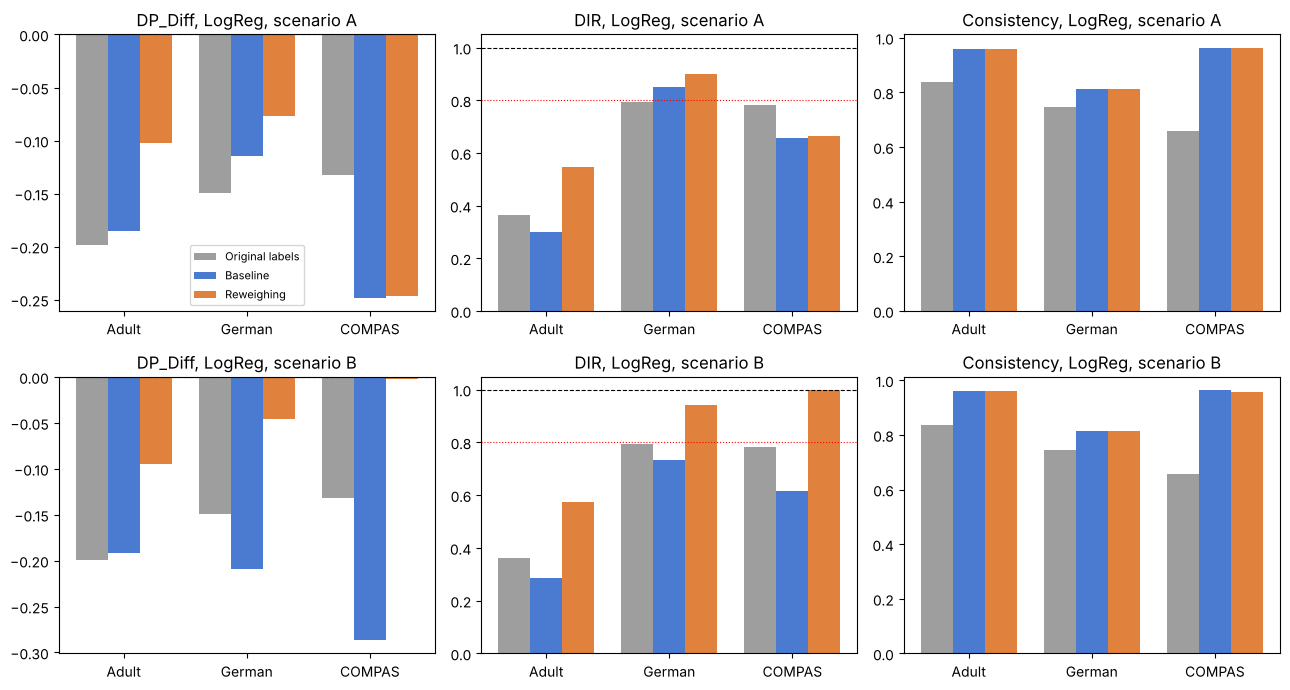

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
stages = ["Original labels", "Baseline", "Reweighing"]
colors = ["#9e9e9e", "#4a7bd0", "#e0823d"]
for row, sc in zip(axes, SCENARIOS):
  for ax, metric, ref in zip(row, ["DP_Diff", "DIR", "Consistency"], [0, 1, None]):
      x = np.arange(len(DATASETS)); wdt = 0.26
      vals = [[before[d][metric] for d in DATASETS],
              [means.loc[(sc, d, "LogReg", "Baseline"), metric] for d in DATASETS],
              [means.loc[(sc, d, "LogReg", "Reweighing"), metric] for d in DATASETS]]
      for i, (s, v) in enumerate(zip(stages, vals)):
          ax.bar(x + (i - 1) * wdt, v, wdt, label=s, color=colors[i])
      if ref is not None: ax.axhline(ref, color="black", lw=0.8, ls="--")
      if metric == "DIR": ax.axhline(0.8, color="red", lw=0.8, ls=":")
      ax.set_xticks(x, list(DATASETS)); ax.set_title(f"{metric}, LogReg, scenario {sc[0]}")
axes[0][0].legend(fontsize=8)
plt.tight_layout(); os.makedirs("figures", exist_ok=True)
plt.savefig("figures/fairness_before_after.png", dpi=200); plt.show()

In [10]:
os.makedirs("results", exist_ok=True)
results.to_csv("results/all_runs.csv", index=False)
pretty.to_csv("results/test_metrics_mean_std.csv")
comparison.round(4).to_csv("results/before_after.csv")
before_df.round(4).to_csv("results/original_labels.csv")
print("saved results/*.csv and figures/fairness_before_after.png")

saved results/*.csv and figures/fairness_before_after.png
